# Disconnected(불연속) 이벤트 상세 분석

이 노트는 전처리 과정에서 **Skip Connected(투명) 이벤트가 제거된 후**, 
여전히 좌표 연결이 끊겨 있는 **Disconnected** 정지 이벤트들을 분석합니다.

**분석 목표:**
1. Disconnected 이벤트가 주로 어떤 상황(유형)에서 발생하는지 파악
2. 궤적 보정(Correction)이 필요한지, 아니면 실제 단절(Out, Foul 등)인지 판단

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

In [13]:
# 데이터 로드 (v5.3 Refined Data - Skip Connected 제거됨)
file_path = '../data/refined/v5.3/preprocessed_data.csv'
df = pd.read_csv(file_path)

# 시간 순 정렬
df = df.sort_values(['game_id', 'period_id', 'time_seconds', 'action_id']).reset_index(drop=True)

print(f"Loaded Rows: {len(df):,}")

Loaded Rows: 439,792


## 1. Disconnected 정지 이벤트 추출

In [14]:
# 정지 이벤트 조건
EPSILON = 1e-4
stationary_mask = (np.abs(df['start_x'] - df['end_x']) < EPSILON) & \
                  (np.abs(df['start_y'] - df['end_y']) < EPSILON)

# 분석용 데이터 준비
cols = ['game_id', 'period_id', 'type_name', 'result_name', 'start_x', 'start_y', 'end_x', 'end_y']
stat_df = df.loc[stationary_mask, cols].copy()

# 전후 좌표 가져오기
stat_df['prev_end_x'] = df.groupby(['game_id', 'period_id'])['end_x'].shift(1)[stationary_mask]
stat_df['prev_end_y'] = df.groupby(['game_id', 'period_id'])['end_y'].shift(1)[stationary_mask]
stat_df['next_start_x'] = df.groupby(['game_id', 'period_id'])['start_x'].shift(-1)[stationary_mask]
stat_df['next_start_y'] = df.groupby(['game_id', 'period_id'])['start_y'].shift(-1)[stationary_mask]

# In Distance & Out Distance
stat_df['dist_in'] = np.sqrt((stat_df['prev_end_x'] - stat_df['start_x'])**2 + 
                             (stat_df['prev_end_y'] - stat_df['start_y'])**2)
stat_df['dist_out'] = np.sqrt((stat_df['end_x'] - stat_df['next_start_x'])**2 + 
                              (stat_df['end_y'] - stat_df['next_start_y'])**2)

# Fully Connected (In < E & Out < E) 제외 -> 나머지가 Disconnected
# 이미 Skip Connected는 제거되었으므로, 남은 것 중 Fully Connected가 아니면 Disconnected임.
is_fully_connected = (stat_df['dist_in'] < EPSILON) & (stat_df['dist_out'] < EPSILON)

disconnected_df = stat_df[~is_fully_connected & stat_df['dist_in'].notna()].copy()

print(f"총 정지 이벤트: {len(stat_df):,}")
print(f"Fully Connected: {is_fully_connected.sum():,} ({is_fully_connected.mean()*100:.1f}%)")
print(f"Disconnected (To Analyze): {len(disconnected_df):,} ({len(disconnected_df)/len(stat_df)*100:.1f}%)")

총 정지 이벤트: 63,060
Fully Connected: 1,997 (3.2%)
Disconnected (To Analyze): 61,062 (96.8%)


## 2. Disconnected 유형 분석
Disconnected 이벤트가 언제(어떤 이벤트) 발생하는지 확인합니다.

C:\Users\user\AppData\Local\Temp\ipykernel_5984\2047673061.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=type_counts.values[:20], y=type_counts.index[:20], palette='magma')


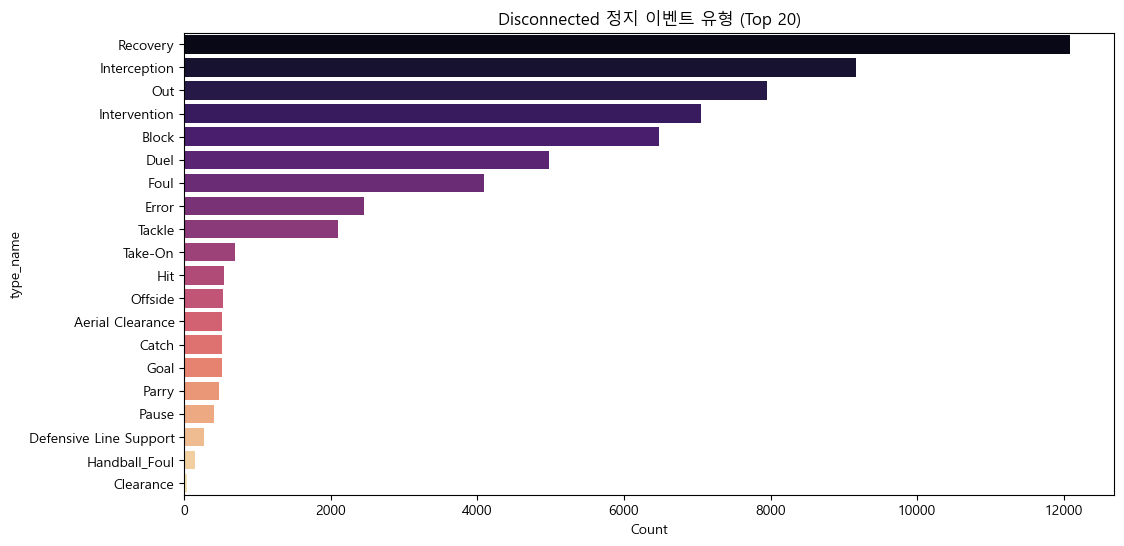

=== Disconnected Event Types (Top 20) ===
type_name
Recovery                  12087
Interception               9164
Out                        7950
Intervention               7050
Block                      6482
Duel                       4972
Foul                       4092
Error                      2450
Tackle                     2103
Take-On                     692
Hit                         542
Offside                     528
Aerial Clearance            520
Catch                       519
Goal                        514
Parry                       474
Pause                       410
Defensive Line Support      264
Handball_Foul               150
Clearance                    40
Name: count, dtype: int64


In [15]:
# 유형별 카운트
type_counts = disconnected_df['type_name'].value_counts()

plt.figure(figsize=(12, 6))
sns.barplot(x=type_counts.values[:20], y=type_counts.index[:20], palette='magma')
plt.title('Disconnected 정지 이벤트 유형 (Top 20)')
plt.xlabel('Count')
plt.show()

print("=== Disconnected Event Types (Top 20) ===")
print(type_counts.head(20))

## 3. 세부 유형 분석: 단절의 원인
Disconnected는 다음 세 가지 경우일 수 있습니다.
1. **Break In**: 들어올 때 끊김 (`dist_in` > 0)
2. **Break Out**: 나갈 때 끊김 (`dist_out` > 0)
3. **Isolated**: 둘 다 끊김

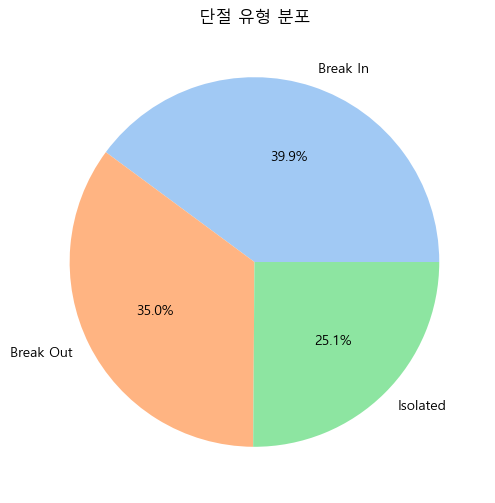

break_type
Break In     24346
Break Out    21382
Isolated     15334
Name: count, dtype: int64


In [16]:
disconnected_df['break_type'] = 'Isolated'
disconnected_df.loc[(disconnected_df['dist_in'] > EPSILON) & (disconnected_df['dist_out'] < EPSILON), 'break_type'] = 'Break In'
disconnected_df.loc[(disconnected_df['dist_in'] < EPSILON) & (disconnected_df['dist_out'] > EPSILON), 'break_type'] = 'Break Out'

break_counts = disconnected_df['break_type'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(break_counts, labels=break_counts.index, autopct='%1.1f%%', colors=sns.color_palette('pastel'))
plt.title('단절 유형 분포')
plt.show()

print(break_counts)

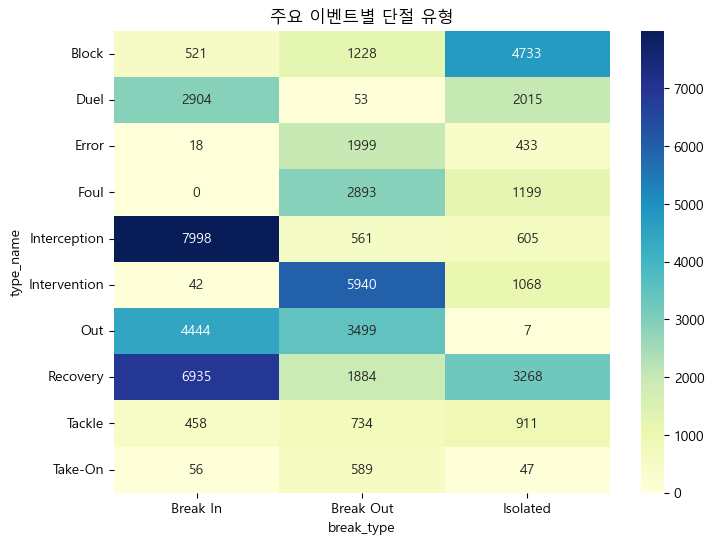

: 

In [ ]:
# 주요 이벤트별 단절 유형 (Heatmap)
top_types = type_counts.head(10).index
heatmap_data = disconnected_df[disconnected_df['type_name'].isin(top_types)]
ct = pd.crosstab(heatmap_data['type_name'], heatmap_data['break_type'])

plt.figure(figsize=(8, 6))
sns.heatmap(ct, annot=True, fmt='d', cmap='YlGnBu')
plt.title('주요 이벤트별 단절 유형')
plt.show()

## 4. 고찰
- **Recovery / Interception**: 공 소유권이 넘어가는 이벤트이므로, 이전 소유자의 마지막 위치와 다를 수 있음 (Break In 정상 가능성).
- **Out**: 공이 나간 위치이므로, 다음 플레이 시작 위치와 다를 수 있음 (Break Out 정상 가능성).
- **Foul**: 파울 지점과 프리킥 지점 차이 발생 가능.

**결론:**
대부분의 Disconnected 이벤트는 축구 경기 규칙상 **자연스러운 단절**일 가능성이 큽니다.
따라서 무리하게 궤적을 잇기보다는, **시퀀스 분리(Split)**의 기준으로 삼는 것이 타당해 보입니다.